# Data Pre-processing and Decision Tree on Unsorted Student Data

**Problem Statement:** Real-world data is usually unsorted and messy (missing values, duplicate rows, outliers, different scales). Before feeding it to a machine learning model it must be pre-processed. In this project we take a raw, unsorted student dataset, clean it step by step, select the best features and then predict whether a student will **Pass or Fail** using a **Decision Tree**.

**Workflow followed in this project**

Raw Data ↓ EDA ↓ Missing Values ↓ Outliers ↓ Feature Scaling ↓ Feature Selection ↓ Clean Data ↓ Machine Learning

## Step 0: Raw Data
Importing the libraries and creating the raw student dataset. The dataset is **unsorted** and, like real data, contains missing values, duplicate rows and outliers.

| Column | Description |
|---|---|
| Student_ID | Unique ID of the student |
| Age | Age in years |
| Attendance | Attendance percentage |
| Study_Hours | Study hours per day |
| Family_Income | Yearly family income (Rs.) |
| Previous_Marks | Marks in the previous exam |
| Sleep_Hours | Sleep hours per day |
| Internet_Access | Yes / No |
| Result | Pass / Fail (target) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Creating the raw dataset (80 students + a few problems added on purpose)
rng = np.random.default_rng(10)
n = 80

df = pd.DataFrame({
    'Student_ID'     : np.arange(101, 101 + n),
    'Age'            : rng.integers(17, 25, n).astype(float),
    'Attendance'     : np.clip(rng.normal(75, 12, n), 35, 100).round(1),
    'Study_Hours'    : np.clip(rng.normal(4, 1.8, n), 0.5, 10).round(1),
    'Family_Income'  : (np.round(rng.lognormal(10.6, 0.35, n) / 500) * 500),
    'Previous_Marks' : np.clip(rng.normal(60, 15, n), 20, 100).round(),
    'Sleep_Hours'    : rng.uniform(4, 9, n).round(1),
    'Internet_Access': rng.choice(['Yes', 'No'], n, p=[0.7, 0.3]),
})

# Result depends mainly on attendance, study hours and previous marks
score = (0.35 * df['Attendance'] + 4 * df['Study_Hours'] + 0.3 * df['Previous_Marks']
         + 3 * (df['Internet_Access'] == 'Yes') + rng.normal(0, 2, n))
df['Result'] = np.where(score > np.percentile(score, 35), 'Pass', 'Fail')

# Problems found in real data: outliers, missing values, duplicate rows
df.loc[[5, 33, 61], 'Family_Income'] = [950000, 1200000, 880000]
df.loc[rng.choice(n, 6, replace=False), 'Attendance'] = np.nan
df.loc[rng.choice(n, 5, replace=False), 'Family_Income'] = np.nan
df.loc[rng.choice(n, 4, replace=False), 'Age'] = np.nan
df.loc[rng.choice(n, 4, replace=False), 'Internet_Access'] = np.nan
df.loc[rng.choice(n, 2, replace=False), 'Result'] = np.nan
df = pd.concat([df, df.iloc[[3, 17, 40, 55]]])

# Shuffle so the data is unsorted
df = df.sample(frac=1, random_state=1).reset_index(drop=True)
df.head(10)

,Student_ID,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours,Internet_Access,Result
0,111,18.0,82.3,1.7,37000.0,58.0,6.0,Yes,Pass
1,168,21.0,NaN,0.9,53500.0,76.0,6.2,Yes,Pass
2,160,22.0,79.6,4.1,33000.0,77.0,4.4,No,Pass
3,134,18.0,68.2,3.2,1200000.0,98.0,6.6,No,Pass
4,156,21.0,76.5,1.4,34000.0,56.0,7.6,Yes,Fail
5,178,20.0,57.4,5.3,23500.0,77.0,8.4,NaN,Pass
6,135,24.0,70.9,2.8,19000.0,78.0,4.4,Yes,Pass
7,139,20.0,74.2,6.6,24500.0,51.0,8.0,Yes,Pass
8,148,24.0,95.7,2.6,30500.0,72.0,6.6,Yes,Pass
9,157,NaN,73.4,0.5,20000.0,69.0,4.4,No,Fail


The Student_IDs above are in random order, so the data is **unsorted**.

### Sort the data
First we sort the data by `Student_ID` so that it is in proper order for further work.

In [3]:
df = df.sort_values('Student_ID').reset_index(drop=True)
df.head(10)

,Student_ID,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours,Internet_Access,Result
0,101,23.0,82.3,7.0,35500.0,61.0,7.9,Yes,Pass
1,102,24.0,71.9,3.7,40500.0,48.0,4.5,No,Fail
2,103,19.0,67.0,6.9,22500.0,51.0,7.7,Yes,Pass
3,104,18.0,66.2,2.7,77500.0,65.0,4.8,No,Fail
4,104,18.0,66.2,2.7,77500.0,65.0,4.8,No,Fail
5,105,23.0,84.2,0.8,29000.0,82.0,7.2,Yes,Pass
6,106,23.0,81.1,5.3,950000.0,51.0,6.2,Yes,Pass
7,107,21.0,69.1,3.9,47000.0,30.0,7.3,No,Fail
8,108,18.0,88.8,4.0,28500.0,53.0,5.4,No,Pass
9,109,23.0,77.2,5.9,37500.0,59.0,4.7,Yes,Pass


## Step 1: EDA (Exploratory Data Analysis)

### Step 1.1 – Number of rows and columns : `df.shape`

In [4]:
print('Rows    :', df.shape[0])
print('Columns :', df.shape[1])
df.shape

Rows    : 84
Columns : 9


(84, 9)

### Step 1.2 – First rows : `df.head()`

In [5]:
df.head()

,Student_ID,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours,Internet_Access,Result
0,101,23.0,82.3,7.0,35500.0,61.0,7.9,Yes,Pass
1,102,24.0,71.9,3.7,40500.0,48.0,4.5,No,Fail
2,103,19.0,67.0,6.9,22500.0,51.0,7.7,Yes,Pass
3,104,18.0,66.2,2.7,77500.0,65.0,4.8,No,Fail
4,104,18.0,66.2,2.7,77500.0,65.0,4.8,No,Fail


### Step 1.3 – Dataset information : `df.info()`
Shows the non-null count and data type of every column.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Student_ID       84 non-null     int64  
 1   Age              80 non-null     float64
 2   Attendance       78 non-null     float64
 3   Study_Hours      84 non-null     float64
 4   Family_Income    79 non-null     float64
 5   Previous_Marks   84 non-null     float64
 6   Sleep_Hours      84 non-null     float64
 7   Internet_Access  80 non-null     str    
 8   Result           82 non-null     str    
dtypes: float64(6), int64(1), str(2)
memory usage: 6.0 KB


### Step 1.4 – Statistical summary : `df.describe()`

In [7]:
df.describe()

,Student_ID,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours
count,84.000000,80.000000,78.000000,84.000000,7.900000e+01,84.000000,84.000000
mean,139.988095,20.562500,72.664103,3.379762,7.678481e+04,61.619048,6.427381
std,23.211180,2.198064,10.694968,1.840428,1.889541e+05,15.038028,1.414073
min,101.000000,17.000000,48.700000,0.500000,1.900000e+04,30.000000,4.000000
25%,119.750000,18.000000,66.275000,1.900000,3.150000e+04,51.000000,5.300000
50%,140.500000,21.000000,72.650000,3.300000,3.900000e+04,60.000000,6.500000
75%,159.250000,23.000000,80.925000,4.525000,4.775000e+04,71.250000,7.700000
max,180.000000,24.000000,99.800000,8.600000,1.200000e+06,98.000000,8.900000


**Observation:** The maximum of `Family_Income` is far greater than its 75th percentile and mean, which points to outliers.

### Step 1.5 – Missing values : `df.isnull().sum()`

In [8]:
df.isnull().sum()

Student_ID         0
Age                4
Attendance         6
Study_Hours        0
Family_Income      5
Previous_Marks     0
Sleep_Hours        0
Internet_Access    4
Result             2
dtype: int64

In [9]:
(df.isnull().sum() / len(df) * 100).round(2)

Student_ID         0.00
Age                4.76
Attendance         7.14
Study_Hours        0.00
Family_Income      5.95
Previous_Marks     0.00
Sleep_Hours        0.00
Internet_Access    4.76
Result             2.38
dtype: float64

### Step 1.6 – Duplicate rows : `df.duplicated().sum()`

In [10]:
print('Duplicate rows:', df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values('Student_ID')

Duplicate rows: 4


,Student_ID,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours,Internet_Access,Result
3,104,18.0,66.2,2.7,77500.0,65.0,4.8,No,Fail
4,104,18.0,66.2,2.7,77500.0,65.0,4.8,No,Fail
18,118,20.0,48.7,1.8,56000.0,98.0,8.4,No,Fail
19,118,20.0,48.7,1.8,56000.0,98.0,8.4,No,Fail
42,141,23.0,78.9,5.8,41500.0,57.0,7.0,Yes,Pass
43,141,23.0,78.9,5.8,41500.0,57.0,7.0,Yes,Pass
58,156,21.0,76.5,1.4,34000.0,56.0,7.6,Yes,Fail
59,156,21.0,76.5,1.4,34000.0,56.0,7.6,Yes,Fail


### Step 1.7 – Distribution : histogram of Attendance

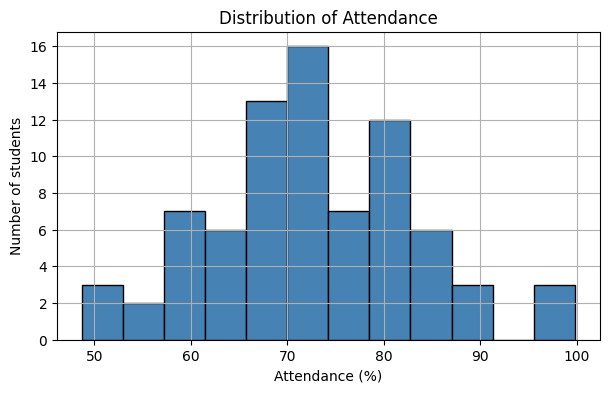

In [11]:
plt.figure(figsize=(7,4))
df['Attendance'].hist(bins=12, color='steelblue', edgecolor='black')
plt.title('Distribution of Attendance')
plt.xlabel('Attendance (%)')
plt.ylabel('Number of students')
plt.show()

**Observation:** Attendance is roughly bell-shaped (normal distribution).

### Step 1.8 – Possible outlier : boxplot of Family_Income

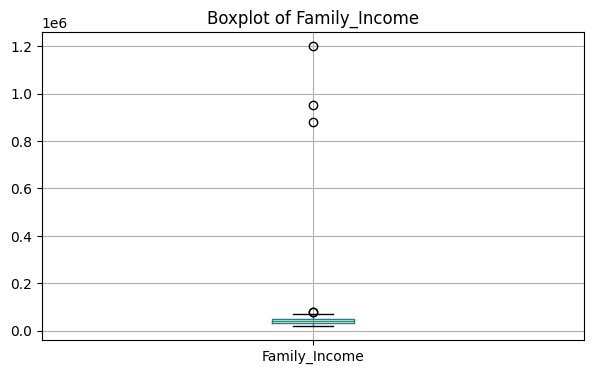

In [12]:
plt.figure(figsize=(7,4))
df.boxplot(column='Family_Income')
plt.title('Boxplot of Family_Income')
plt.show()

**Observation:** A few points lie far above the whiskers. These are outliers (very high family income).

## Step 2: Handling Missing Values

There are two ways to handle missing values:
1. **Remove the row** – used when the value is missing in the target column or when very few rows are affected.
2. **Fill the missing values** – use
   - **Mean** → if the data is normally distributed
   - **Median** → if the data is skewed or has heavy outliers
   - **Mode** → for categorical data

First we check the skewness to decide between mean and median.

In [13]:
df[['Age', 'Attendance', 'Study_Hours', 'Family_Income', 'Previous_Marks', 'Sleep_Hours']].skew().round(2)

Age               0.03
Attendance        0.04
Study_Hours       0.45
Family_Income     5.06
Previous_Marks    0.38
Sleep_Hours      -0.06
dtype: float64

`Attendance` has skewness close to 0 (normal), so we use the **mean**. `Family_Income` is heavily skewed with outliers, so we use the **median**. `Internet_Access` is categorical, so we use the **mode**. `Age` is a whole number, so we use the median. Rows with a missing **Result** (target) cannot be used for learning, so we **remove** them.

In [14]:
# 1. Remove rows where the target is missing
df = df.dropna(subset=['Result'])

# 2. Fill missing values
df['Attendance']      = df['Attendance'].fillna(df['Attendance'].mean())
df['Family_Income']   = df['Family_Income'].fillna(df['Family_Income'].median())
df['Age']             = df['Age'].fillna(df['Age'].median())
df['Internet_Access'] = df['Internet_Access'].fillna(df['Internet_Access'].mode()[0])

print('Missing values left:', df.isnull().sum().sum())

Missing values left: 0


### Removing duplicate rows

In [15]:
df = df.drop_duplicates().reset_index(drop=True)
print('Duplicate rows left:', df.duplicated().sum())
print('Shape now:', df.shape)

Duplicate rows left: 0
Shape now: (78, 9)


## Step 3: Outlier Detection and Treatment

**Detection – IQR method**

- IQR = Q3 − Q1
- Lower limit = Q1 − 1.5 × IQR
- Upper limit = Q3 + 1.5 × IQR

Any value outside these limits is an outlier.

In [16]:
num_cols = ['Age', 'Attendance', 'Study_Hours', 'Family_Income', 'Previous_Marks', 'Sleep_Hours']

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col:15s} lower = {lower:10.2f}  upper = {upper:10.2f}  outliers = {count}')

Age             lower =      13.00  upper =      29.00  outliers = 0
Attendance      lower =      47.20  upper =     100.00  outliers = 0
Study_Hours     lower =      -1.40  upper =       8.00  outliers = 1
Family_Income   lower =    9187.50  upper =   68687.50  outliers = 5
Previous_Marks  lower =      19.50  upper =     101.50  outliers = 0
Sleep_Hours     lower =       1.74  upper =      11.24  outliers = 0


`Family_Income` has the most outliers (very high incomes) and `Study_Hours` has one mild outlier. All other columns have none.

**Treatment – Capping:** Instead of deleting the students, we replace the extreme values with the lower/upper limit. This keeps all the rows and reduces the effect of the outliers.

In [17]:
print('Max Family_Income before capping:', df['Family_Income'].max())

for col in ['Study_Hours', 'Family_Income']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower, upper)

print('Max Family_Income after capping :', df['Family_Income'].max())
print('Max Study_Hours after capping   :', df['Study_Hours'].max())

Max Family_Income before capping: 1200000.0
Max Family_Income after capping : 68687.5
Max Study_Hours after capping   : 7.999999999999999


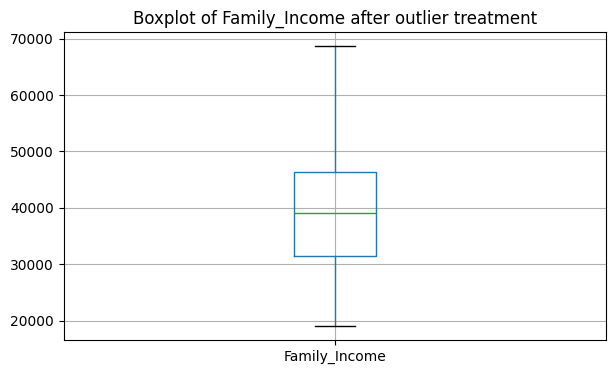

In [18]:
plt.figure(figsize=(7,4))
df.boxplot(column='Family_Income')
plt.title('Boxplot of Family_Income after outlier treatment')
plt.show()

## Step 4: Choose X and y

- `Student_ID` is only an identifier, so it is **not** a feature and is removed.
- `Internet_Access` is text (Yes/No), so it is converted to numbers (Yes = 1, No = 0).
- **y (target)** = Result (Pass = 1, Fail = 0)

In [19]:
df['Internet_Access'] = df['Internet_Access'].map({'Yes': 1, 'No': 0})
y = df['Result'].map({'Pass': 1, 'Fail': 0})
X = df.drop(columns=['Student_ID', 'Result'])

print('X shape:', X.shape)
print('y shape:', y.shape)
print()
print(y.value_counts())
X.head()

X shape: (78, 7)
y shape: (78,)

Result
1    51
0    27
Name: count, dtype: int64


,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours,Internet_Access
0,23.0,82.3,7.0,35500.0,61.0,7.9,1
1,24.0,71.9,3.7,40500.0,48.0,4.5,0
2,19.0,67.0,6.9,22500.0,51.0,7.7,1
3,18.0,66.2,2.7,68687.5,65.0,4.8,0
4,23.0,84.2,0.8,29000.0,82.0,7.2,1


## Step 5: Feature Scaling

Different columns have very different ranges, for example **Age is about 17 to 24** while **Family_Income is in tens of thousands**. A column with big numbers can dominate the others in many algorithms. Feature scaling converts all columns to a similar range.

There are two common techniques:

| Technique | Formula | Result |
|---|---|---|
| **Normalization** (Min-Max) | (x − min) / (max − min) | values between 0 and 1 |
| **Standardization** (Z-score) | (x − mean) / standard deviation | mean = 0, standard deviation = 1 (centres data around 0) |

In [20]:
cols_to_scale = ['Age', 'Attendance', 'Study_Hours', 'Family_Income', 'Previous_Marks', 'Sleep_Hours']
print('Before scaling:')
X[cols_to_scale].describe().loc[['mean', 'std', 'min', 'max']].round(2)

Before scaling:


,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours
mean,20.63,72.57,3.39,40031.25,60.96,6.39
std,2.17,9.80,1.83,12581.06,14.67,1.41
min,17.00,48.70,0.50,19000.00,30.00,4.00
max,24.00,95.80,8.00,68687.50,98.00,8.90


### Normalization

In [21]:
X_norm = X.copy()
X_norm[cols_to_scale] = MinMaxScaler().fit_transform(X[cols_to_scale])
X_norm[cols_to_scale].describe().loc[['mean', 'std', 'min', 'max']].round(2)

,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours
mean,0.52,0.51,0.39,0.42,0.46,0.49
std,0.31,0.21,0.24,0.25,0.22,0.29
min,0.00,0.00,0.00,0.00,0.00,0.00
max,1.00,1.00,1.00,1.00,1.00,1.00


After normalization every column lies between **0 and 1**.

### Standardization

In [22]:
X_std = X.copy()
X_std[cols_to_scale] = StandardScaler().fit_transform(X[cols_to_scale])
X_std[cols_to_scale].describe().loc[['mean', 'std', 'min', 'max']].round(2)

,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours
mean,0.00,0.00,0.00,0.00,0.00,0.00
std,1.01,1.01,1.01,1.01,1.01,1.01
min,-1.68,-2.45,-1.60,-1.68,-2.12,-1.70
max,1.56,2.38,2.54,2.29,2.54,1.79


After standardization the **mean of every column is 0** and the **standard deviation is 1**. We use the standardized data for the next steps.

In [23]:
X_scaled = X_std.copy()
X_scaled.head()

,Age,Attendance,Study_Hours,Family_Income,Previous_Marks,Sleep_Hours,Internet_Access
0,1.100625,0.998640,1.987270,-0.362496,0.002639,1.076904,1
1,1.564673,-0.069218,0.168197,0.037500,-0.889372,-1.343392,0
2,-0.755564,-0.572343,1.932146,-1.402483,-0.683523,0.934534,1
3,-1.219612,-0.654486,-0.383037,2.292473,0.277104,-1.129837,0
4,1.100625,1.193729,-1.430382,-0.882490,1.443580,0.578608,1


## Step 6: Feature Selection

Feature selection means **selecting the relevant variables for the best possible prediction and removing unnecessary columns**. It makes the model simpler, faster and less likely to overfit.

Three techniques are used here: **Correlation, RFE (Recursive Feature Elimination) and Random Forest importance**.

### Technique 1: Correlation
Columns that have a strong correlation with the target are useful.

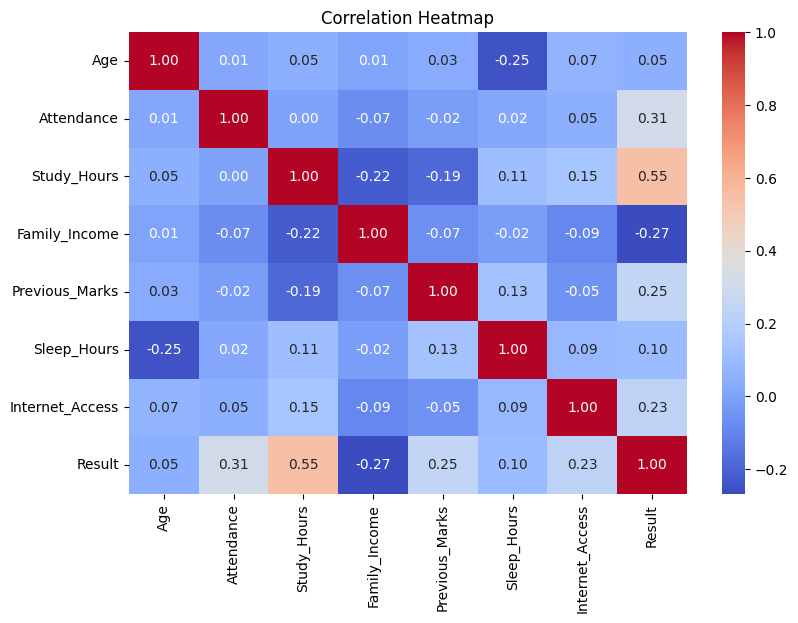

In [24]:
corr_data = X_scaled.copy()
corr_data['Result'] = y

plt.figure(figsize=(9,6))
sns.heatmap(corr_data.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [25]:
corr_with_target = corr_data.corr()['Result'].drop('Result').abs().sort_values(ascending=False)
corr_with_target.round(3)

Study_Hours        0.546
Attendance         0.307
Family_Income      0.268
Previous_Marks     0.251
Internet_Access    0.229
Sleep_Hours        0.101
Age                0.050
Name: Result, dtype: float64

### Technique 2: RFE (Recursive Feature Elimination)
RFE trains a model, removes the weakest feature, and repeats until the required number of features remain.

In [26]:
rfe = RFE(estimator=LogisticRegression(), n_features_to_select=3)
rfe.fit(X_scaled, y)

rfe_result = pd.DataFrame({'Feature': X_scaled.columns,
                           'Selected': rfe.support_,
                           'Rank': rfe.ranking_}).sort_values('Rank')
rfe_result

,Feature,Selected,Rank
1,Attendance,True,1
2,Study_Hours,True,1
4,Previous_Marks,True,1
6,Internet_Access,False,2
3,Family_Income,False,3
0,Age,False,4
5,Sleep_Hours,False,5


### Technique 3: Random Forest feature importance
A random forest is a collection of many decision trees. It tells how much each feature helped in making the predictions.

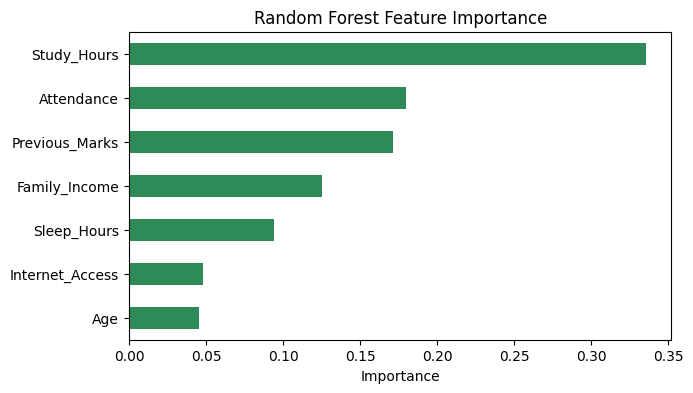

Study_Hours        0.335
Attendance         0.180
Previous_Marks     0.171
Family_Income      0.126
Sleep_Hours        0.094
Internet_Access    0.048
Age                0.045
dtype: float64

In [27]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_scaled, y)

importance = pd.Series(rf.feature_importances_, index=X_scaled.columns).sort_values()
importance.plot(kind='barh', color='seagreen', figsize=(7,4))
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.show()
importance.sort_values(ascending=False).round(3)

### Final feature selection

| Technique | Top features |
|---|---|
| Correlation | Study_Hours, Attendance, Family_Income |
| RFE (top 3) | Attendance, Study_Hours, Previous_Marks |
| Random Forest | Study_Hours, Attendance, Previous_Marks |

**Study_Hours**, **Attendance** and **Previous_Marks** are selected by RFE and Random Forest, and they are also strong in the correlation list. `Family_Income` shows some correlation but RFE and Random Forest both rank it low, so it is not reliable. `Sleep_Hours`, `Age` and `Internet_Access` have little importance. So the unnecessary columns **Family_Income, Sleep_Hours, Age and Internet_Access are removed**.

In [28]:
selected_features = ['Attendance', 'Study_Hours', 'Previous_Marks']
X_final = X_scaled[selected_features]
print('Selected features:', selected_features)
X_final.head()

Selected features: ['Attendance', 'Study_Hours', 'Previous_Marks']


,Attendance,Study_Hours,Previous_Marks
0,0.998640,1.987270,0.002639
1,-0.069218,0.168197,-0.889372
2,-0.572343,1.932146,-0.683523
3,-0.654486,-0.383037,0.277104
4,1.193729,-1.430382,1.443580


## Step 7: Clean Data
The data is now clean: no missing values, no duplicates, outliers treated, features scaled and only the relevant features kept.

In [29]:
print('Shape of final data :', X_final.shape)
print('Missing values      :', X_final.isnull().sum().sum())
print('Duplicate rows      :', X_final.duplicated().sum())

Shape of final data : (78, 3)
Missing values      : 0
Duplicate rows      : 0


## Step 8: Machine Learning – Decision Tree

A **decision tree** is a tree-based model that makes predictions by **asking a sequence of questions** (for example *"Is Attendance above 0.1?"*). Each answer sends the student down one branch until a final decision is reached.

### Parts of a Decision Tree

| Part | Meaning |
|---|---|
| **Root node** | The first question at the top of the tree; it contains all the data |
| **Decision (internal) node** | A node that asks a further question and splits the data |
| **Branch** | The arrow showing the answer (Yes/No, True/False) to a question |
| **Leaf node** | The end node that gives the final prediction (Pass or Fail) |

### How does the tree choose the best option (best split)?
At every node the tree tries all possible questions and picks the one that separates the classes most cleanly. The purity of a node is measured by **Gini Impurity**:

**Gini = 1 − (p_pass² + p_fail²)**

- Gini = 0 → perfectly pure node (all students are Pass or all are Fail)
- Gini = 0.5 → completely mixed node (50% Pass, 50% Fail)

The question that gives the **largest decrease in Gini** (called information gain when entropy is used) is chosen as the split.

### Split into Train and Test (75% / 25%)

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X_final, y, test_size=0.25, random_state=42, stratify=y)
print('Training samples:', X_train.shape[0])
print('Testing samples :', X_test.shape[0])

Training samples: 58
Testing samples : 20


### Gini impurity of the root node (example)

In [31]:
p = y_train.value_counts(normalize=True)
gini_root = 1 - (p ** 2).sum()
print('Proportion of Pass/Fail in training data:')
print(p.round(3))
print()
print('Gini impurity of root node:', round(gini_root, 4))

Proportion of Pass/Fail in training data:
Result
1    0.655
0    0.345
Name: proportion, dtype: float64

Gini impurity of root node: 0.4518


### Train the Decision Tree
`max_depth=3` keeps the tree small so it is easy to read and does not overfit.

In [32]:
tree = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
tree.fit(X_train, y_train)
print('Decision Tree trained')

Decision Tree trained


### Visualise the Tree

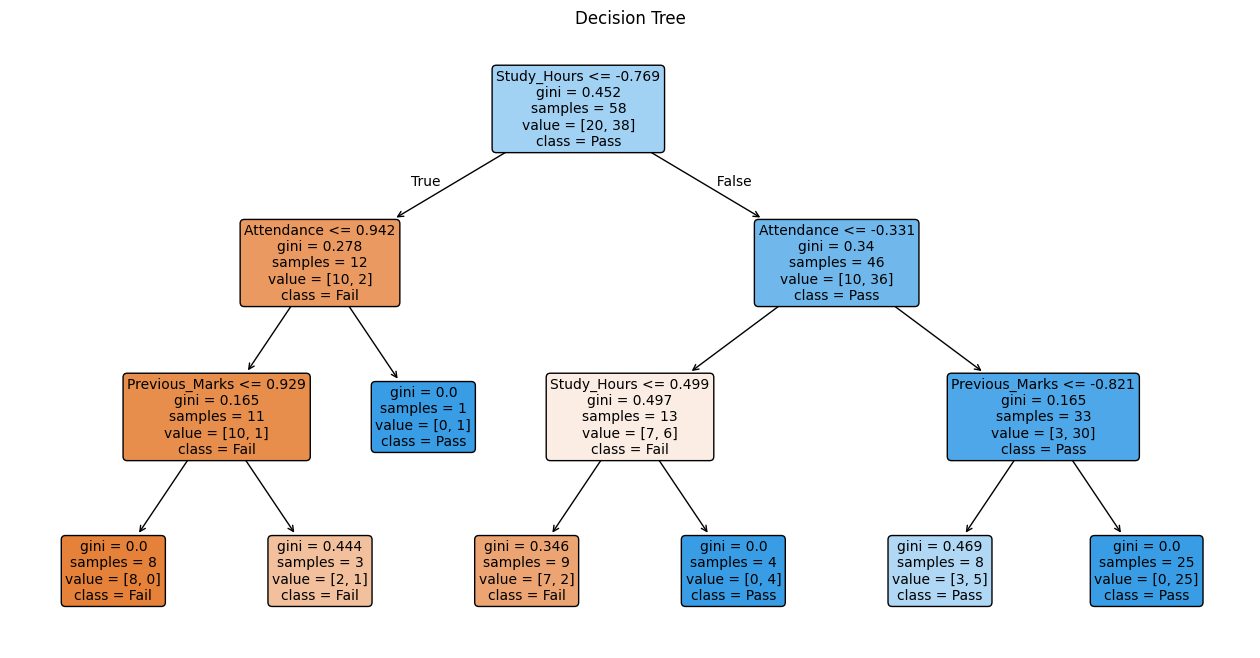

In [33]:
plt.figure(figsize=(16,8))
plot_tree(tree, feature_names=X_final.columns, class_names=['Fail', 'Pass'],
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree')
plt.show()

In the tree, the top box is the **root node**, the boxes below it are **decision nodes**, the lines are **branches** and the boxes at the bottom are **leaf nodes**. Each box also shows its Gini value, the number of samples and the class.

### Make Predictions and Evaluate

In [34]:
y_pred = tree.predict(X_test)

print('Train Accuracy:', round(tree.score(X_train, y_train), 4))
print('Test Accuracy :', round(accuracy_score(y_test, y_pred), 4))

Train Accuracy: 0.8966
Test Accuracy : 0.75


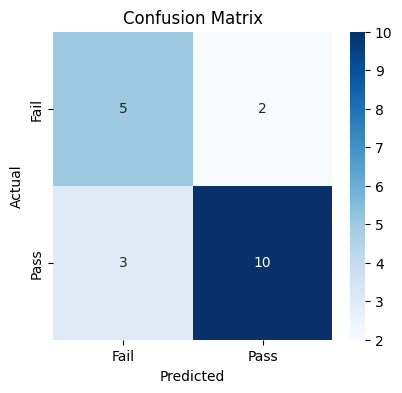

In [35]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4.5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fail', 'Pass'], yticklabels=['Fail', 'Pass'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [36]:
print(classification_report(y_test, y_pred, target_names=['Fail', 'Pass']))

              precision    recall  f1-score   support

        Fail       0.62      0.71      0.67         7
        Pass       0.83      0.77      0.80        13

    accuracy                           0.75        20
   macro avg       0.73      0.74      0.73        20
weighted avg       0.76      0.75      0.75        20



In [37]:
comparison = pd.DataFrame({'Actual': y_test.map({1: 'Pass', 0: 'Fail'}).values,
                           'Predicted': pd.Series(y_pred).map({1: 'Pass', 0: 'Fail'}).values})
comparison.head(10)

,Actual,Predicted
0,Fail,Pass
1,Pass,Pass
2,Fail,Fail
3,Pass,Fail
4,Pass,Pass
5,Pass,Fail
6,Pass,Pass
7,Fail,Pass
8,Pass,Pass
9,Pass,Pass


## Conclusion

- The raw student data was unsorted and had missing values, duplicate rows and outliers. It was cleaned step by step following the pre-processing workflow: EDA → missing values → outliers → feature scaling → feature selection → clean data.
- Missing values were filled using the **mean** (normal data), **median** (skewed data) and **mode** (categorical data), and rows with a missing target were removed.
- Outliers in `Family_Income` were detected with the IQR method and treated by capping.
- Normalization and standardization were applied to bring all features to a similar scale.
- Correlation, RFE and Random Forest importance were used to select the most relevant features.
- The final selected features are **Attendance, Study_Hours and Previous_Marks**; the other columns were removed as unnecessary.
- A **Decision Tree** (max depth 3) was trained on the clean data. It reached about 90% accuracy on training data and **75% on test data**, so it predicts Pass/Fail reasonably well using only three features.

**Limitations**
- The dataset is small (about 75 students), so the accuracy can change if the train/test split changes.
- Scaling and feature selection were done on the full data before splitting. In a production project they should be fitted on the training data only to avoid data leakage.
- A single decision tree can overfit. A depth limit was used to control this.

**Future Scope**
- Use a larger real-world dataset.
- Try Random Forest or Gradient Boosting and compare accuracy.
- Use a Pipeline and cross-validation for more reliable results.